# 14-FreeRTOS互斥信号量与优先级继承


## 1. 本篇内容与学习目标

本篇对应 `19互斥信号量.pptx`，学习 FreeRTOS 互斥信号量如何保护共享资源、保证临界访问的原子性，并理解优先级反转与优先级继承机制。

课程主线包括：互斥信号量的定义与特性、核心 API、共享资源冲突案例、优先级反转演示、优先级继承、与二值信号量的区别，以及使用注意事项。主课件共13页，第13页为品牌结束页，教学内容覆盖第1—12页。

示例代码用于解释 API 和调度关系，没有把课件中的板级工程、任务栈大小或运行结果扩展为已验证事实。


## 2. 什么是互斥信号量

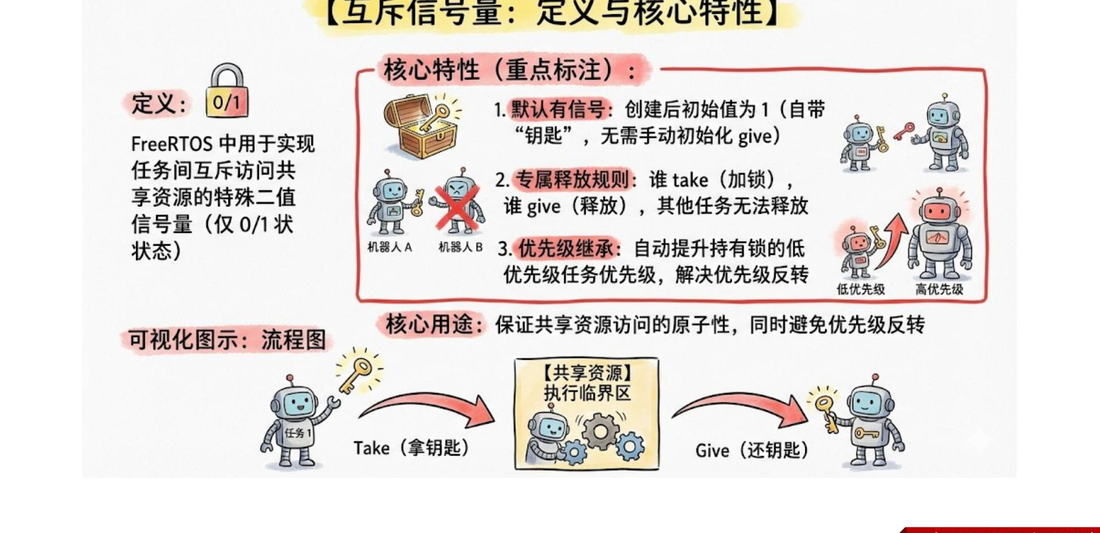

互斥信号量（Mutex）是一种用于保护共享资源的同步对象，状态通常为“可用/已占用”。它与二值信号量都只有0/1状态，但 Mutex 具有额外语义：

- 创建后默认有信号，表示资源可用。
- 成功 `Take` 的任务成为持有者，只有持有者可以 `Give`。
- 内核可以在高优先级任务等待时临时提升持有者的优先级，降低优先级反转的影响。

共享资源可以是全局变量、外设寄存器、显示缓冲区或一段需要连续执行的临界操作。Mutex 保护的是访问过程，不负责传输数据。


## 3. 互斥信号量核心 API

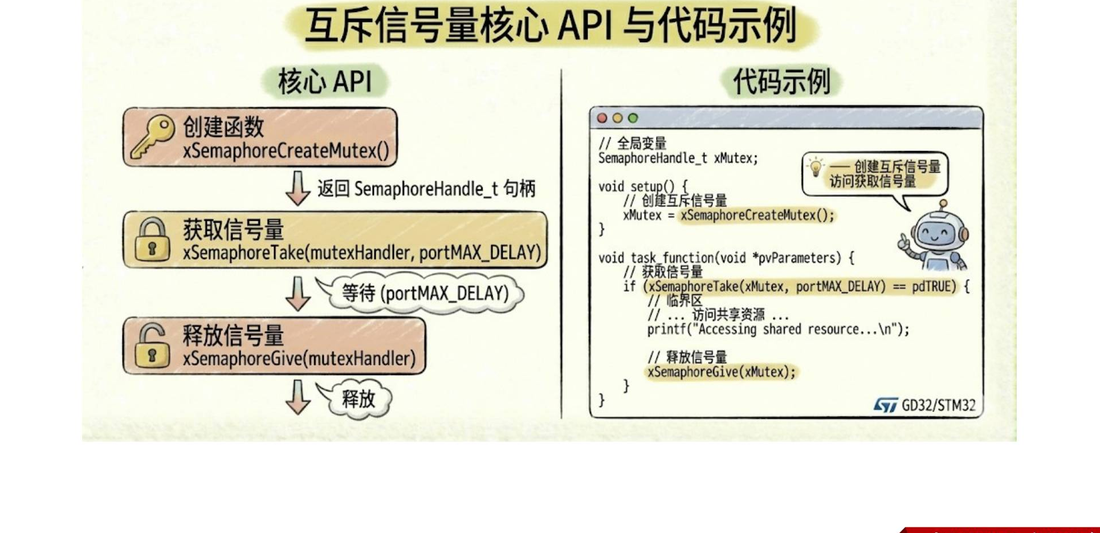

典型使用流程如下：

```c
SemaphoreHandle_t mutexHandler;

mutexHandler = xSemaphoreCreateMutex();
if (mutexHandler == NULL) {
    handle_create_error();
}

if (xSemaphoreTake(mutexHandler, portMAX_DELAY) == pdPASS) {
    access_shared_resource();
    xSemaphoreGive(mutexHandler);
}
```

- `xSemaphoreCreateMutex()`：创建互斥信号量，成功时返回 `SemaphoreHandle_t`，失败返回 `NULL`。
- `xSemaphoreTake()`：申请资源，可设置阻塞时间；成功后任务获得持有权。
- `xSemaphoreGive()`：释放资源，应由当前持有者调用。

动态创建会消耗 FreeRTOS 堆空间，必须检查返回值。`portMAX_DELAY` 是否代表无限等待，仍取决于 `INCLUDE_vTaskSuspend` 等配置；示例只表达等待意图。


## 4. 共享资源冲突：为什么需要互斥

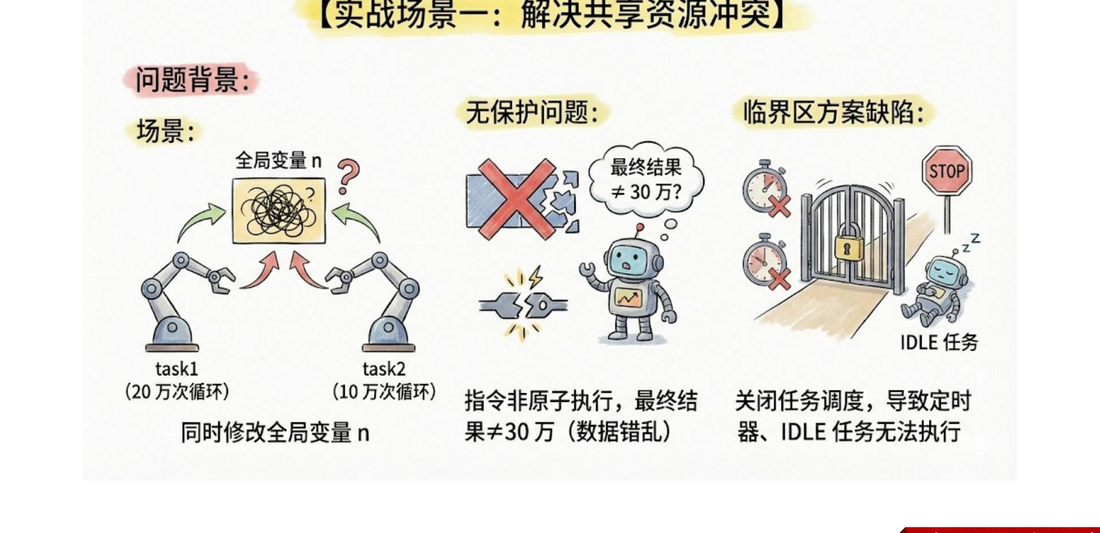

假设两个任务同时对全局变量 `n` 做“读取—加一—写回”：

```c
// 错误示意：多个任务并发执行，操作可能交错
int temp = n;
task_delay_or_preemption();
n = temp + 1;
```

两个任务都读到相同的旧值时，最终写回的结果会丢失一次更新。类似问题也会出现在多个任务同时操作同一个串口发送缓冲区、显示设备或文件对象时。

临界区方案可以暂时禁止抢占或中断，但会扩大不可调度时间；互斥信号量把共享资源的访问范围显式化，并允许其他不依赖该资源的任务继续运行。


## 5. 用互斥信号量保证原子访问

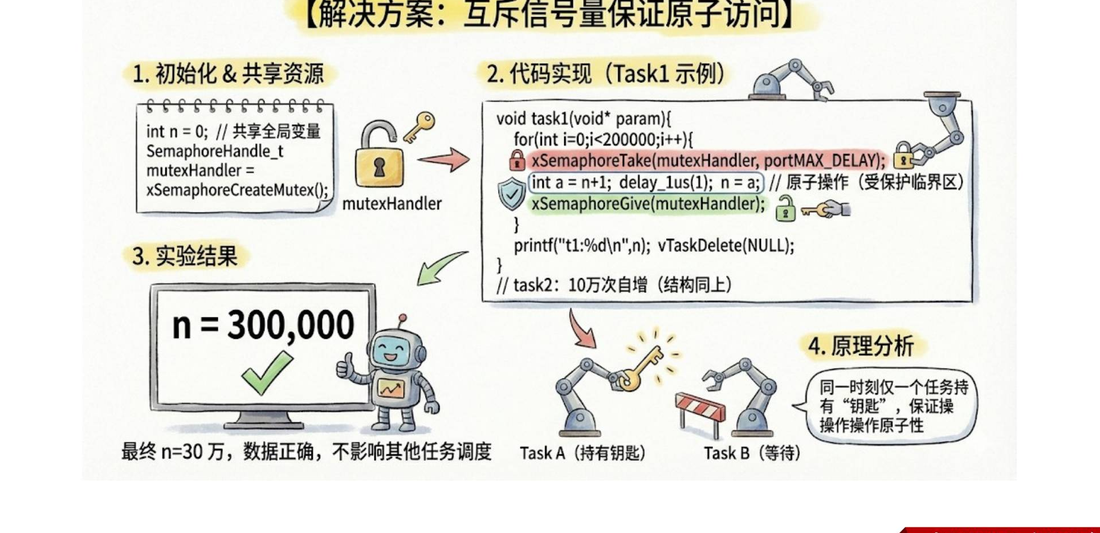

保护共享资源时，要把完整的“读取—修改—写回”放在 Take 与 Give 之间：

```c
void task1(void *param)
{
    for (;;) {
        if (xSemaphoreTake(mutexHandler, portMAX_DELAY) == pdPASS) {
            int temp = n;
            delay_inside_demo();       // 仅用于演示持锁期间不可被其他任务进入
            n = temp + 1;
            xSemaphoreGive(mutexHandler);
        }
        task_delay_outside_critical_section();
    }
}
```

课件示例用两个任务累加全局变量，说明加锁后每次只有一个任务能进入共享资源区域。实际工程中应缩短持锁时间，避免在锁内执行阻塞 I/O、长时间延时或不必要的计算。

即使任务在等待 Mutex 时被阻塞，调度器仍可以运行其他任务；但依赖同一资源的任务会按获取顺序继续竞争。


## 6. 什么是优先级反转

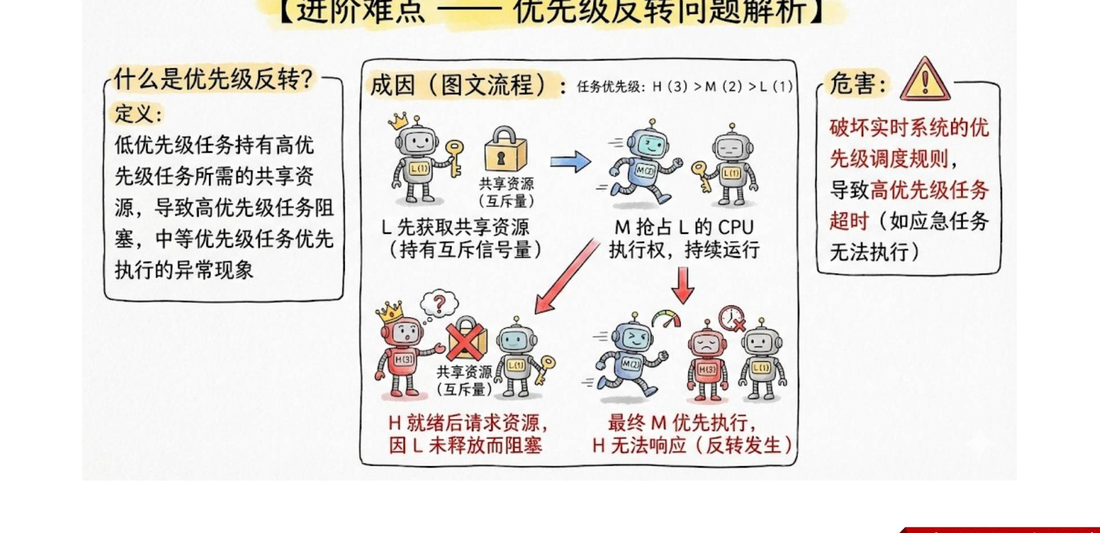

优先级反转指的是：高优先级任务需要的共享资源被低优先级任务持有，而中优先级任务持续运行，导致低优先级任务迟迟无法运行并释放资源，高优先级任务反而长期等待。

典型过程：

1. 低优先级任务 L 先获取 Mutex。
2. 高优先级任务 H 请求同一个 Mutex，被阻塞。
3. 中优先级任务 M 抢占 CPU，L 得不到运行机会。
4. H 只能继续等待，出现“高优先级任务被低优先级任务间接拖延”的现象。

这会破坏实时性。它不是简单的“任务优先级设置错了”，而是共享资源与抢占调度共同造成的时序问题。


## 7. 优先级继承如何缓解反转

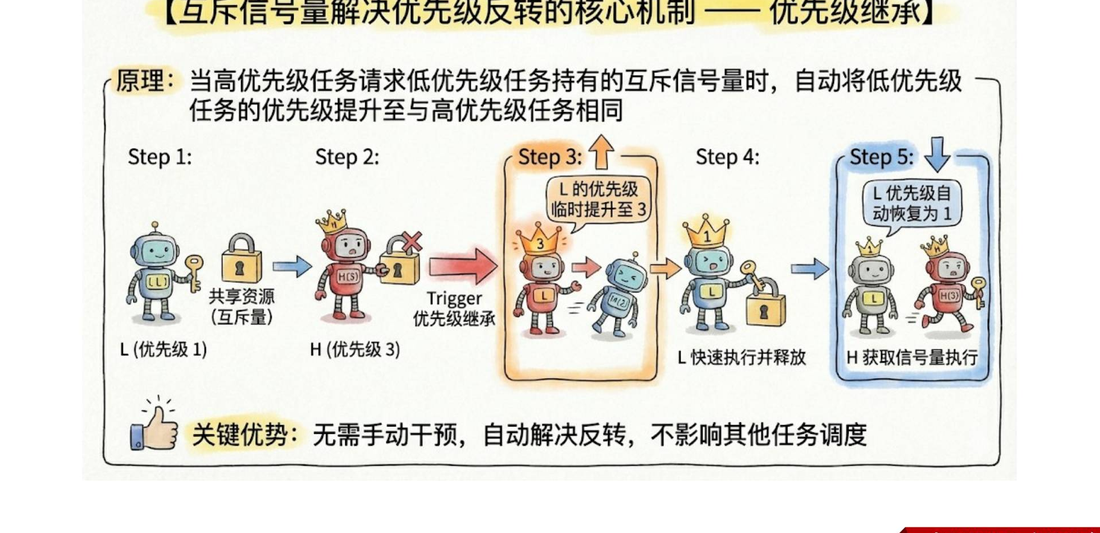

FreeRTOS Mutex 支持优先级继承：当高优先级任务 H 因等待 Mutex 被阻塞时，内核临时把持有 Mutex 的低优先级任务 L 提升到接近 H 的优先级，使 L 能尽快运行、完成临界区并释放 Mutex。

流程可以概括为：

```text
L 获取 Mutex
    ↓
H 请求同一 Mutex，被阻塞
    ↓
L 临时继承 H 的优先级
    ↓
L 尽快完成临界区并 Give
    ↓
L 恢复原优先级，H 获得 Mutex 后继续执行
```

优先级继承降低了阻塞时间，但不等于所有实时问题都自动消失。持锁任务仍应尽快释放，避免嵌套多个锁，并评估多个资源之间的锁顺序。


## 8. 互斥信号量与二值信号量对比

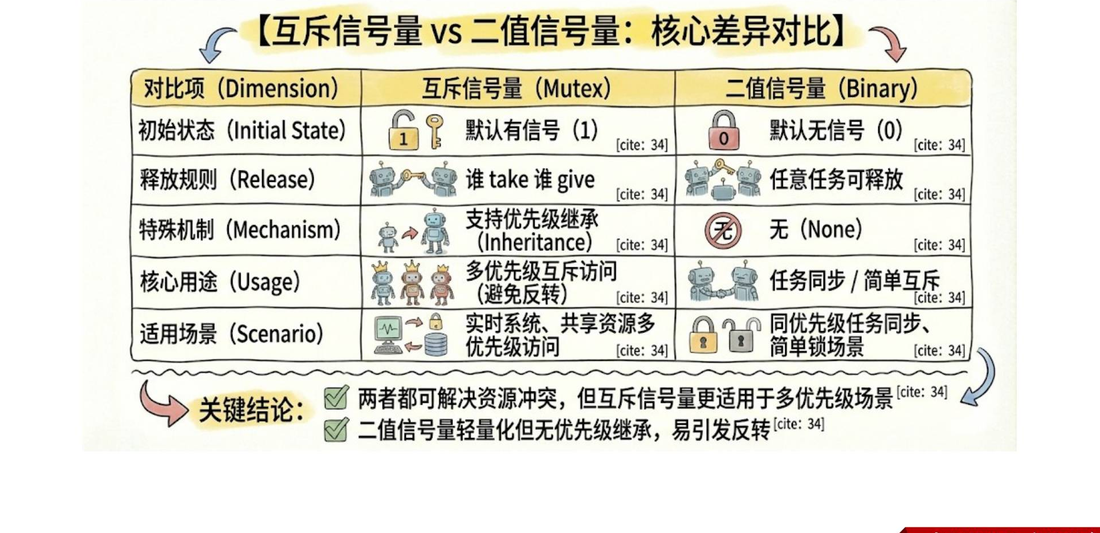

| 对比项 | 互斥信号量 | 二值信号量 |
|---|---|---|
| 初始状态 | 通常创建后可用，计数为1 | 常见创建后为0，需要发送方 Give |
| 释放规则 | 持有者释放，具有所有权 | 任意合适的任务可释放，用于通知 |
| 特殊机制 | 支持优先级继承 | 不支持优先级继承 |
| 典型用途 | 保护共享资源、避免优先级反转 | 任务同步、事件通知、简单互斥场景 |
| ISR 使用 | 不能在 ISR 中 Take/Give | 事件通知可使用 FromISR 版本 |

如果问题是“谁可以访问这段共享资源”，优先考虑 Mutex；如果问题是“某个事件是否发生”，优先考虑二值信号量。两者都不能替代消息队列的数据传输功能。


## 9. 常见问题与使用注意事项

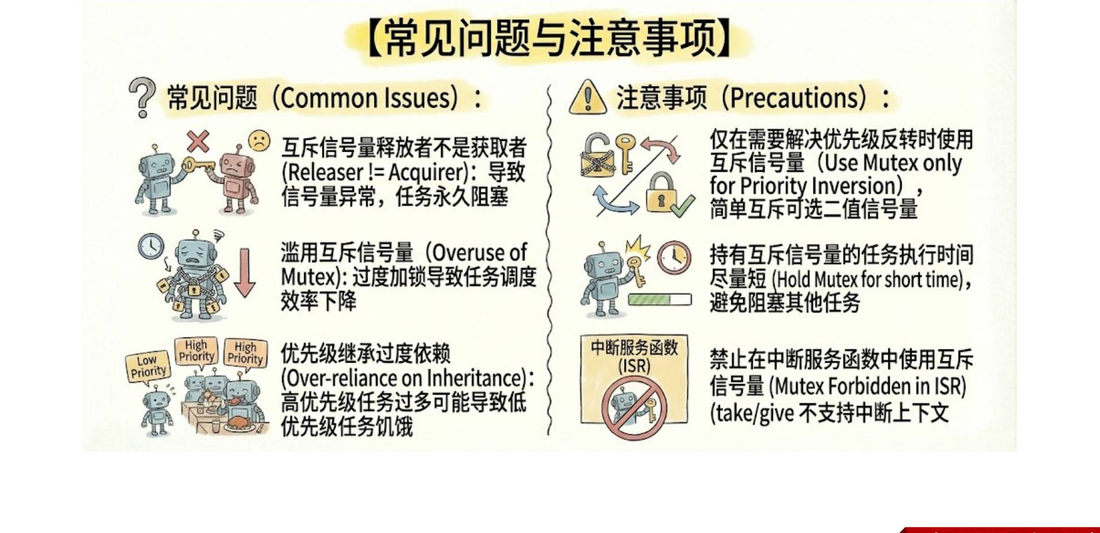

### 不要由非持有者释放

Mutex 有所有权语义。由另一个任务代替释放可能破坏内核状态，造成后续任务永久等待。任务应设计清晰的“谁 Take、谁 Give”路径。

### 持锁时间要短

不要在持有 Mutex 时调用长时间阻塞的 I/O、无限等待另一个同步对象或执行大段计算，否则会拖延所有等待者。

### 不能在 ISR 中使用 Mutex

中断服务函数不能执行会阻塞的 Mutex 操作，也不能依赖优先级继承。ISR 应通过 FromISR API 通知任务，由任务完成资源访问。

### 处理嵌套锁顺序

多个 Mutex 同时使用时，所有任务应遵循一致的获取顺序，避免“任务A持有锁1等待锁2、任务B持有锁2等待锁1”的死锁。


## 10. 配置、验证与调试建议

在工程中使用 Mutex 前，应确认内核配置允许互斥信号量，并检查动态分配或静态分配方式。具体宏名称取决于 FreeRTOS 版本和工程配置，不能只凭课件中的单个宏判断全部功能。

建议按以下顺序验证：

1. 创建 Mutex 后检查句柄是否为 `NULL`。
2. 让两个任务访问同一资源，观察未加锁时的数据错误，再观察加锁后的结果。
3. 在调试日志中记录 Take 成功、等待超时和 Give 路径。
4. 模拟 L、M、H 三个优先级任务，确认等待 Mutex 时是否出现长时间阻塞，并检查优先级继承是否生效。
5. 用运行时间统计或 trace 工具确认持锁时间，避免把 Mutex 当作覆盖整个任务循环的“大锁”。

这些步骤是验证方法，不代表已经在具体开发板上执行过。


## 11. 核心总结

- **本质**：Mutex 是带有所有权语义的二值同步对象，用于保护共享资源。
- **流程**：创建 `xSemaphoreCreateMutex()`，使用 `xSemaphoreTake()` 获取，访问完成后由持有者 `xSemaphoreGive()`。
- **实时性**：优先级反转会让高优先级任务间接等待低优先级任务；Mutex 的优先级继承能促使持有者尽快释放资源。
- **边界**：Mutex 不用于 ISR，不负责传递数据，也不能代替合理的锁顺序和短临界区设计。
- **选型**：资源保护用 Mutex；事件通知用二值信号量；多事件或多资源数量管理用计数信号量。

本篇依据课程 PPT 整理，未进行开发板编译、下载或运行验证。
